# FairLens - Model Training & Analysis (Google Colab)
**AI-powered resume screening - R.M.K. Engineering College, Product Development Lab 1**

This notebook contains the complete machine-learning part of FairLens:

1. Load the *Resume Screening Dataset* and explore it
2. Show why duplicates must be removed (data-leakage check)
3. Pre-process text (identifier masking, cleaning, stop-words, spaCy lemmatisation)
4. TF-IDF features + **KNN** classifier, tuning K, hold-out and 5-fold evaluation
5. Learn the **keyword bank** of every job category from the dataset
6. Map a typed **job title** to a dataset category
7. Evaluate the whole **screening pipeline** (ranking + shortlisting) and an ablation study
8. Save the model files that the Streamlit app (`app.py`) loads

**How to run in Colab:** upload `FairLens.zip` when asked in the first cell, then *Runtime > Run all*.

## 0. Setup

In [1]:
import os, sys, subprocess
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', '-q', 'install', 'pymupdf', 'spacy', 'nltk', 'reportlab', 'plotly'])
    subprocess.run([sys.executable, '-m', 'spacy', 'download', 'en_core_web_sm', '-q'])
    from google.colab import files
    print('Upload FairLens.zip'); up = files.upload()
    subprocess.run(['unzip', '-oq', list(up)[0], '-d', '/content'])
    os.chdir('/content/FairLens')
elif os.path.basename(os.getcwd()) == 'notebooks':   # running locally from VS Code / Jupyter
    os.chdir('..')
print('Working directory:', os.getcwd())

Working directory: /home/claude/FairLens


In [2]:
import warnings, json, time
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

from fairlens import config, training as T
from fairlens.model import fit_artifacts, make_vectorizer, make_knn
from fairlens.preprocess import preprocess_many, mask_identifiers
from fairlens.titles import TitleResolver
os.makedirs('analysis', exist_ok=True)
sns.set_theme(style='whitegrid')

## 1. Dataset

In [3]:
raw = T.load_dataset(dedupe=False)
df  = T.load_dataset()                      # duplicates removed
print(f'Rows in CSV           : {len(raw)}')
print(f'Unique resumes        : {len(df)}   ({len(raw)-len(df)} duplicate rows removed)')
print(f'Job categories        : {df.Category.nunique()}')
print(f'Avg. resume length    : {df.Resume.str.split().str.len().mean():.0f} words')
df.head(3)

Rows in CSV           : 962
Unique resumes        : 166   (796 duplicate rows removed)
Job categories        : 25
Avg. resume length    : 425 words


,Category,Resume
0,Data Science,Skills * Programming Languages: Python (pandas...
1,Data Science,Education Details \nMay 2013 to May 2017 B.E ...
2,Data Science,"Areas of Interest Deep Learning, Control Syste..."


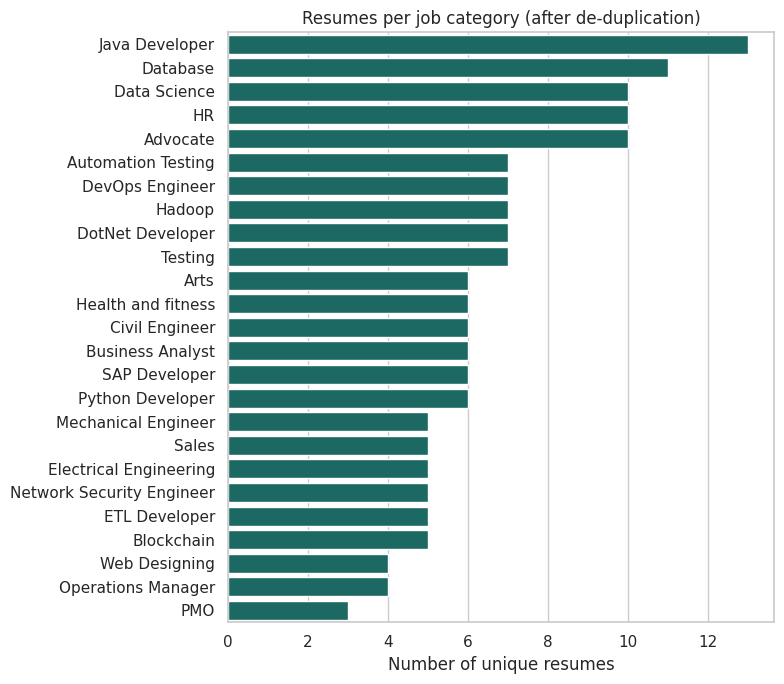

In [4]:
counts = df.Category.value_counts()
plt.figure(figsize=(8, 7)); sns.barplot(x=counts.values, y=counts.index, color='#0f766e')
plt.xlabel('Number of unique resumes'); plt.ylabel(''); plt.title('Resumes per job category (after de-duplication)')
plt.tight_layout(); plt.savefig('analysis/class_distribution.png', dpi=150); plt.show()

## 2. Pre-processing

In [5]:
t0 = time.time()
df, surface = T.preprocess_dataset(df)       # mask identifiers -> clean -> stop-words -> spaCy lemmas
print(f'Pre-processed {len(df)} resumes in {time.time()-t0:.1f}s')
i = 3
print('RAW  :', df.Resume[i][:300].replace(chr(10), ' '), '...')
print('CLEAN:', df.clean[i][:300], '...')

Pre-processed 166 resumes in 8.8s
RAW  : Skills â¢ R â¢ Python â¢ SAP HANA â¢ Tableau â¢ SAP HANA SQL â¢ SAP HANA PAL â¢ MS SQL â¢ SAP Lumira â¢ C# â¢ Linear Programming â¢ Data Modelling â¢ Advance Analytics â¢ SCM Analytics â¢ Retail Analytics â¢Social Media Analytics â¢ NLP Education Details  January 2017 to January 2018 ...
CLEAN: skill python sap hana tableau sap hana sql sap hana pal ms sql sap lumira csharp linear programming data modelling advance analytics scm analytics retail analytics social media analytics nlp education details january january pgdm business analytics great lakes institute management illinois institute ...


In [6]:
# Identifier masking demo (fictional resume header)
demo = "Priya Raman\npriya.raman@example.com | +91 9876543210 | Gender: Female\nPython developer 2018 - 2022"
print(mask_identifiers(demo))

(' \n  |   |  \nPython developer 2018 - 2022', 4)


## 3. Why we de-duplicate (data-leakage check)
The public CSV has 962 rows but only 166 are unique - the same resume appears many times.
If we split *with* the duplicates, many test resumes also exist in the training set and accuracy looks
unrealistically high. All FairLens results therefore use the **de-duplicated** data.

In [7]:
clean_map = dict(zip(df.Resume, df.clean))
raw['clean'] = raw.Resume.map(clean_map)
tr, te = train_test_split(raw, test_size=0.2, stratify=raw.Category, random_state=config.RANDOM_STATE)
vec = make_vectorizer(); knn = make_knn(5).fit(vec.fit_transform(tr.clean), tr.Category)
leaky = accuracy_score(te.Category, knn.predict(vec.transform(te.clean)))
print(f'Test resumes that also appear in the training set : {te.Resume.isin(tr.Resume).mean()*100:.1f}%')
print(f'Accuracy WITH duplicates (inflated, not trustworthy): {leaky*100:.1f}%')

Test resumes that also appear in the training set : 99.5%
Accuracy WITH duplicates (inflated, not trustworthy): 99.5%


## 4. Train / test split, TF-IDF and tuning K for KNN

train: 132  test: 34
 K  cv_accuracy
 1     0.750000
 3     0.765152
 5     0.787879
 7     0.757576
 9     0.787879
Selected K = 9


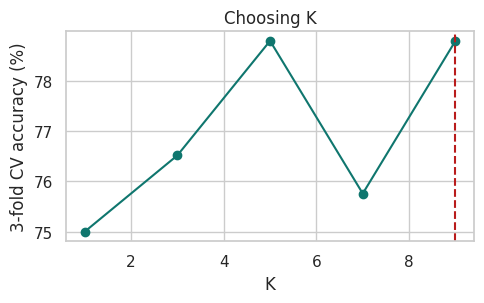

In [8]:
train, test = T.split(df)
print('train:', len(train), ' test:', len(test))
best_k, ktab = T.tune_knn(train.clean, train.Category)
print(ktab.to_string(index=False)); print('Selected K =', best_k)
plt.figure(figsize=(5, 3.2)); plt.plot(ktab.K, ktab.cv_accuracy*100, marker='o', color='#0f766e')
plt.axvline(best_k, ls='--', c='#b91c1c'); plt.xlabel('K'); plt.ylabel('3-fold CV accuracy (%)'); plt.title('Choosing K')
plt.tight_layout(); plt.savefig('analysis/k_selection.png', dpi=150); plt.show()

## 5. Train the final model and evaluate on the held-out test set

In [9]:
art = fit_artifacts(train.clean, train.Category, best_k, surface)     # TF-IDF + KNN + keyword bank + calibration
res = T.evaluate_classifier(art, test.clean, test.Category)
holdout = pd.DataFrame({'Metric': ['Accuracy', 'Precision (weighted)', 'Recall (weighted)', 'F1-score (weighted)', 'Selected K'],
                        'Value': [f"{res['accuracy']*100:.2f}%", f"{res['precision']*100:.2f}%", f"{res['recall']*100:.2f}%",
                                  f"{res['f1']*100:.2f}%", best_k]})
holdout

,Metric,Value
0,Accuracy,76.47%
1,Precision (weighted),71.32%
2,Recall (weighted),76.47%
3,F1-score (weighted),71.76%
4,Selected K,9


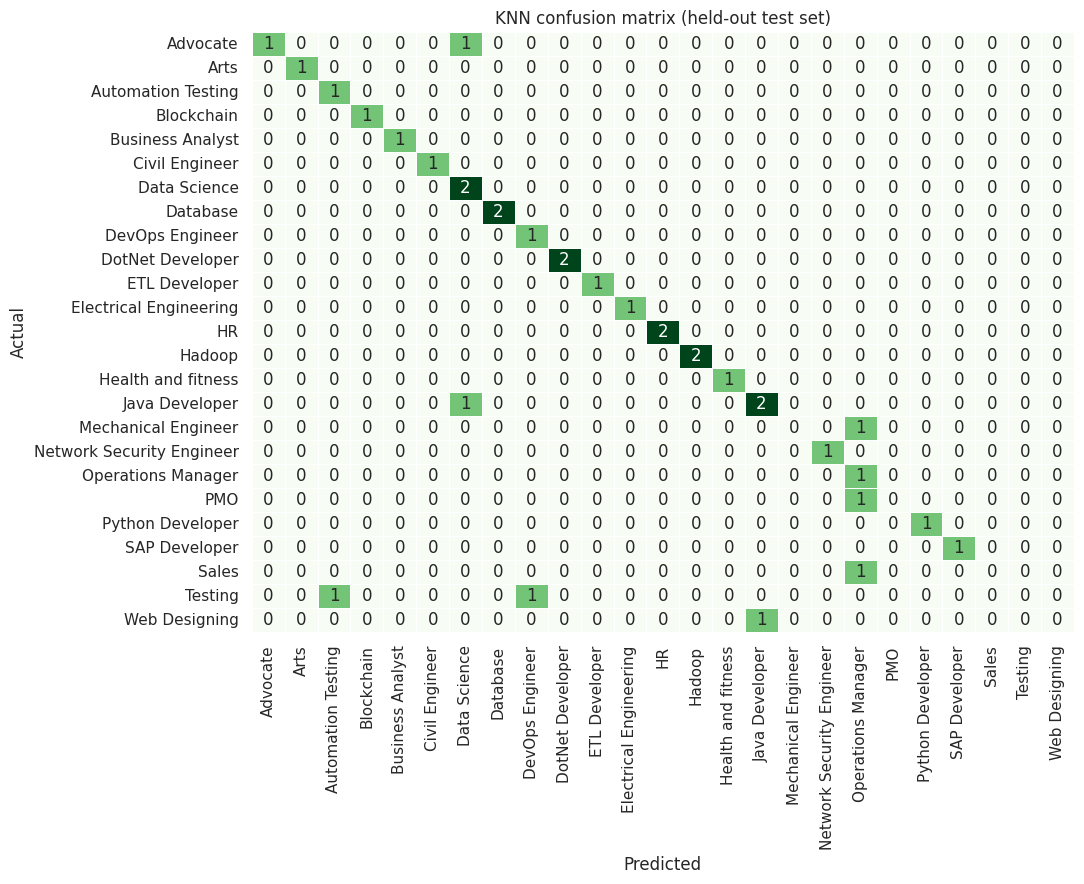

,precision,recall,f1-score,support
Advocate,1.00,0.50,0.67,2.0
Arts,1.00,1.00,1.00,1.0
Automation Testing,0.50,1.00,0.67,1.0
Blockchain,1.00,1.00,1.00,1.0
Business Analyst,1.00,1.00,1.00,1.0
Civil Engineer,1.00,1.00,1.00,1.0
Data Science,0.50,1.00,0.67,2.0
Database,1.00,1.00,1.00,2.0
DevOps Engineer,0.50,1.00,0.67,1.0
DotNet Developer,1.00,1.00,1.00,2.0


In [10]:
cm = pd.DataFrame(res['confusion'], index=art.classes, columns=art.classes)
plt.figure(figsize=(11, 9)); sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False, linewidths=.4)
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('KNN confusion matrix (held-out test set)')
plt.tight_layout(); plt.savefig('analysis/confusion_matrix.png', dpi=150); plt.show()
rep = pd.DataFrame(res['report']).T.drop(['accuracy', 'macro avg', 'weighted avg'], errors='ignore')
rep[['precision', 'recall', 'f1-score']] = rep[['precision', 'recall', 'f1-score']].round(2)
rep

In [11]:
cv = T.cv_classifier(df, best_k)
print(f"5-fold cross-validation  accuracy = {cv['acc_mean']*100:.1f}% +/- {cv['acc_std']*100:.1f}   F1 = {cv['f1_mean']*100:.1f}% +/- {cv['f1_std']*100:.1f}")

5-fold cross-validation  accuracy = 76.5% +/- 3.4   F1 = 73.1% +/- 3.5


## 6. Keyword bank learned from the dataset
For every job category the model keeps the 20 terms that are **common in that category's resumes and rare in the others**
(coverage x log-lift). When the HR user types a job title, these are the keywords searched in every uploaded resume.

In [12]:
from fairlens.preprocess import display_term
for c in ['Data Science', 'Python Developer', 'Java Developer', 'HR', 'Web Designing', 'Database']:
    kws = list(dict.fromkeys(display_term(k['term'], art.surface) for k in art.bank[c]))
    print(f'{c:18s}', ', '.join(kws))

Data Science       machine, analytics, deep, learning, detection, decision, sentiment, reduction, nlp, predictive, python, text, scientist, science, processing, classification, intelligence, visualization, recommendations
Python Developer   python developer, git, web crawling, restful API, REST, django, numpy, controller, languages python, web service, database mysql, mongodb, design development, utilizing, selected, HTML CSS, cycle, agile, unit testing, version
Java Developer     spring, hibernate, JSP, j2ee, java developer, servlet, eclipse, JQUERY AJAX, MVC, frontend, salcluster, middleware, angular, core java, development web, august july, jdbc, keeping track, amravati, mysql
HR                 HR, mba, attendance, records, policies, leave, salary, training need, manpower, hospitality, compliance related, conduct training, diploma hotel, compensation, economics, training development, creating job, pf, human resource, honesty
Web Designing      designer web, graphics, incorporated, 

## 7. Job-title -> category resolver

In [13]:
resolver = TitleResolver(art)
title_acc, ttab = T.title_test(resolver, T.TITLE_CASES)
print(f'Title resolver accuracy on {len(ttab)} test titles: {title_acc*100:.1f}%')
for t in ['Senior Data Scientist', 'Java Full Stack Developer', 'HR Executive']:
    r = resolver.resolve(t); print(f'{t:28s} ->', r['category'], f"({r['confidence']:.2f})")
ttab.head(10)

Title resolver accuracy on 40 test titles: 100.0%
Senior Data Scientist        -> Data Science (1.00)
Java Full Stack Developer    -> Java Developer (0.72)
HR Executive                 -> HR (1.00)


,title,expected,resolved,confidence,correct
0,Senior Data Scientist,Data Science,Data Science,1.00,True
1,Machine Learning Engineer,Data Science,Data Science,1.00,True
2,HR Executive,HR,HR,1.00,True
3,Talent Acquisition Specialist,HR,HR,0.85,True
4,Corporate Lawyer,Advocate,Advocate,0.75,True
5,Senior Java Programmer,Java Developer,Java Developer,1.00,True
6,Java Full Stack Developer,Java Developer,Java Developer,0.72,True
7,Python Backend Developer,Python Developer,Python Developer,0.75,True
8,Django Developer,Python Developer,Python Developer,1.00,True
9,Hadoop Big Data Developer,Hadoop,Hadoop,0.89,True


## 8. Evaluate the complete screening pipeline (out-of-fold)
For every fold and every job category, the held-out resumes are screened for that job; a resume is *relevant* if its true
category equals the job category. We report ranking quality (MRR, Hit@1, Hit@3) for each scoring variant (ablation) and
tune the shortlist cut-off + KNN category gate by F1.

In [14]:
rank_tab, sl = T.pipeline_cv(df, best_k)
rank_tab.round(3)

,MRR,Hit@1,Hit@3
Skill (keywords) only,0.826,0.727,0.934
Similarity only,0.920,0.876,0.950
KNN only,0.922,0.876,0.967
Skill + Similarity,0.890,0.826,0.942
FairLens score (5 factors),0.699,0.612,0.752
FairLens score + category gate,0.862,0.810,0.901


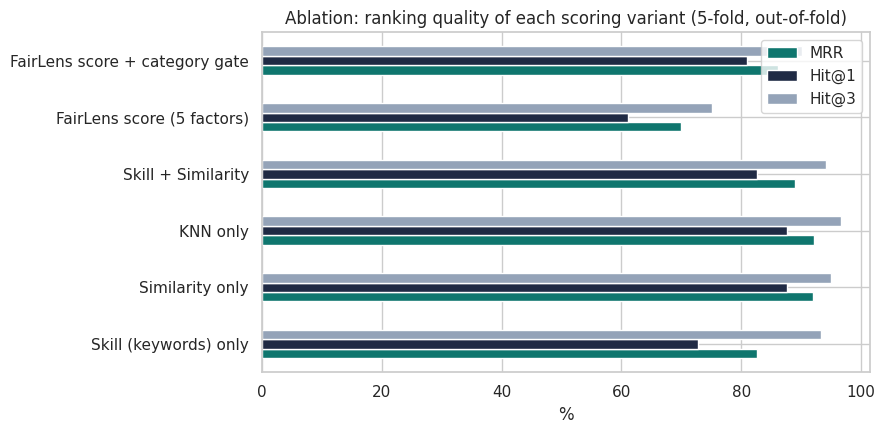

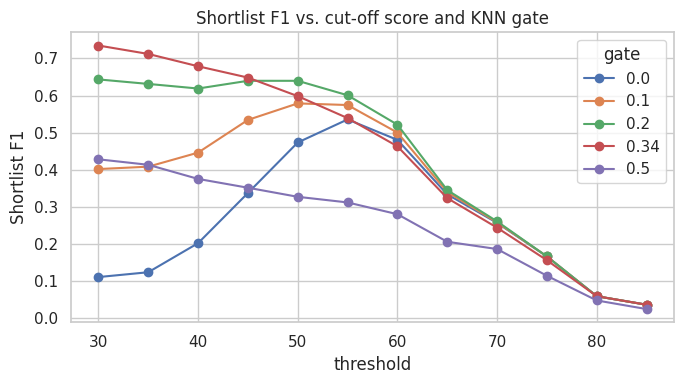

Chosen shortlist rule: {'threshold': 30.0, 'gate': 0.34, 'precision': 0.8888888888888888, 'recall': 0.6265060240963856, 'f1': 0.7349823321554769}


In [15]:
ax = (rank_tab[['MRR', 'Hit@1', 'Hit@3']] * 100).plot.barh(figsize=(9, 4.5), color=['#0f766e', '#1f2a44', '#94a3b8'])
ax.set_xlabel('%'); ax.set_title('Ablation: ranking quality of each scoring variant (5-fold, out-of-fold)')
plt.tight_layout(); plt.savefig('analysis/ablation.png', dpi=150); plt.show()
piv = sl.pivot(index='threshold', columns='gate', values='f1')
piv.plot(marker='o', figsize=(7, 4)); plt.ylabel('Shortlist F1'); plt.title('Shortlist F1 vs. cut-off score and KNN gate')
plt.tight_layout(); plt.savefig('analysis/threshold_f1.png', dpi=150); plt.show()
best = sl.sort_values(['f1', 'precision'], ascending=False).iloc[0]
print('Chosen shortlist rule:', best.to_dict())

## 9. Save the model for the Streamlit app

In [16]:
art.threshold, art.gate = float(best.threshold), float(best.gate)
art.meta = {'k': best_k, 'train_size': len(train), 'test_size': len(test)}
art.save()
metrics = {'unique_resumes': len(df), 'raw_rows': len(raw), 'categories': df.Category.nunique(), 'k': best_k,
           'k_table': ktab.to_dict('records'), 'leaky_accuracy': leaky,
           'holdout': {m: res[m] for m in ['accuracy', 'precision', 'recall', 'f1']}, 'cv': cv,
           'ranking': rank_tab.to_dict('index'), 'shortlist_best': best.to_dict(), 'title_accuracy': title_acc}
config.METRICS_FILE.write_text(json.dumps(metrics, indent=2, default=float))
import shutil; shutil.make_archive('fairlens_models', 'zip', 'models'); print('Saved:', os.listdir('models'))
if IN_COLAB:
    from google.colab import files; files.download('fairlens_models.zip')   # copy the files into FairLens/models/ in VS Code

Saved: ['keyword_bank.json', 'metrics.json', 'benchmark.json', 'fairlens_model.joblib']


## 10. Try it: screen the sample PDF resumes for a job title

In [17]:
from pathlib import Path
from fairlens.engine import ScreeningEngine
from fairlens.parser import pdf_to_text
eng = ScreeningEngine(art)
title = 'Data Scientist'
m = eng.resolve_title(title); print(title, '->', m['category'])
docs = [{'name': p.name, 'text': pdf_to_text(p.read_bytes())} for p in sorted(Path('sample_resumes').glob('*.pdf'))]
out = eng.screen(m['category'], docs)
out[['rank', 'file_name', 'final_score', 'skill_score', 'similarity_score', 'category_probability', 'predicted_category', 'decision']]

Data Scientist -> Data Science


,rank,file_name,final_score,skill_score,similarity_score,category_probability,predicted_category,decision
0,1,Resume_02.pdf,59.6,0.609,0.651,0.684,Data Science,Shortlisted
1,2,Resume_01.pdf,54.3,0.097,0.756,0.352,Data Science,Shortlisted
2,3,Resume_09.pdf,57.2,0.360,0.502,0.102,Hadoop,Not shortlisted
3,4,Resume_04.pdf,47.4,0.055,0.379,0.108,Java Developer,Not shortlisted
4,5,Resume_03.pdf,47.0,0.139,0.404,0.109,Python Developer,Not shortlisted
5,6,Resume_13.pdf,42.7,0.000,0.268,0.000,Operations Manager,Not shortlisted
6,7,Resume_08.pdf,41.6,0.042,0.325,0.000,ETL Developer,Not shortlisted
7,8,Resume_14.pdf,39.9,0.000,0.315,0.000,DevOps Engineer,Not shortlisted
8,9,Resume_10.pdf,38.4,0.000,0.255,0.107,Java Developer,Not shortlisted
9,10,Resume_12.pdf,38.3,0.000,0.253,0.000,Database,Not shortlisted
